«Исследование и сравнение методов понижения размерности и кластеризации на реальном высокоразмерном датасете (из области по выбору: биоинформатика, тексты, изображения, графы) с анализом устойчивости и интерпретируемости полученных кластеров».

Основные требования к проекту:

Выбор и обоснование одного или двух реальных высокоразмерных датасетов (например, single‑cell RNA‑seq, embedding‑представления текстов, feature‑описания изображений)
Построение и сравнение нескольких пайплайнов «DR → кластеризация» (минимум 3 DR‑метода и 3 алгоритма кластеризации) с оценкой качества, устойчивости и практической интерпретации кластеров.

# Проект: Mice Protein Expression

Для проекта выбран **Mice Protein Expression** — реальный биоинформатический набор измерений уровней экспрессии белков в коре головного мозга мышей. Он содержит 1080 наблюдений и 77 числовых белковых признаков, поэтому позволяет проверить методы понижения размерности в условиях высокой размерности, коррелированности и пропусков.

Метки восьми экспериментальных групп используются только для внешней оценки и последующей интерпретации. Признаки `Genotype`, `Treatment`, `Behavior`, `class` и идентификатор `MouseID` исключены из матрицы.

In [ ]:
import os
import sys
import time
import warnings
from pathlib import Path

numba_cache = Path(".numba_cache").resolve()
numba_cache.mkdir(exist_ok=True)
os.environ["NUMBA_CACHE_DIR"] = str(numba_cache)
os.environ["LOKY_MAX_CPU_COUNT"] = str(os.cpu_count() or 1)
os.environ["OMP_NUM_THREADS"] = "1"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, LabelEncoder, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.manifold import Isomap, TSNE, trustworthiness
from sklearn.cluster import KMeans, AgglomerativeClustering, Birch
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score, calinski_harabasz_score, davies_bouldin_score,
    adjusted_rand_score, adjusted_mutual_info_score,
    homogeneity_score, completeness_score, v_measure_score
)

sys.modules["tensorflow"] = None
from umap import UMAP

warnings.filterwarnings("ignore", category=FutureWarning)
plt.style.use("seaborn-v0_8-whitegrid")
sns.set_palette("tab10")
RANDOM_STATE = 42

## 1. Загрузка и исследование данных

In [2]:
data_path = Path("../lab4/Data_Cortex_Nuclear.xls")
if not data_path.exists():
    data_path = Path("clustering/lab4/Data_Cortex_Nuclear.xls")

df = pd.read_excel(data_path)
protein_cols = df.select_dtypes(include="number").columns.tolist()
metadata_cols = ["MouseID", "Genotype", "Treatment", "Behavior", "class"]

dataset_summary = pd.DataFrame({
    "Показатель": ["Объекты", "Все столбцы", "Белковые признаки", "Классы", "Пропущенные значения"],
    "Значение": [len(df), df.shape[1], len(protein_cols), df["class"].nunique(), int(df[protein_cols].isna().sum().sum())]
})
display(dataset_summary)
display(df[metadata_cols].head())

missing = df[protein_cols].isna().sum().sort_values(ascending=False)
print(f"Признаков с пропусками: {(missing > 0).sum()} из {len(protein_cols)}")
display(missing[missing > 0].rename("Число пропусков").to_frame().head(15))

,Показатель,Значение
0,Объекты,1080
1,Все столбцы,82
2,Белковые признаки,77
3,Классы,8
4,Пропущенные значения,1396


,MouseID,Genotype,Treatment,Behavior,class
0,309_1,Control,Memantine,C/S,c-CS-m
1,309_2,Control,Memantine,C/S,c-CS-m
2,309_3,Control,Memantine,C/S,c-CS-m
3,309_4,Control,Memantine,C/S,c-CS-m
4,309_5,Control,Memantine,C/S,c-CS-m


Признаков с пропусками: 49 из 77


,Число пропусков
BCL2_N,285
H3MeK4_N,270
BAD_N,213
EGR1_N,210
H3AcK18_N,180
pCFOS_N,75
ELK_N,18
Bcatenin_N,18
MEK_N,7
P38_N,3


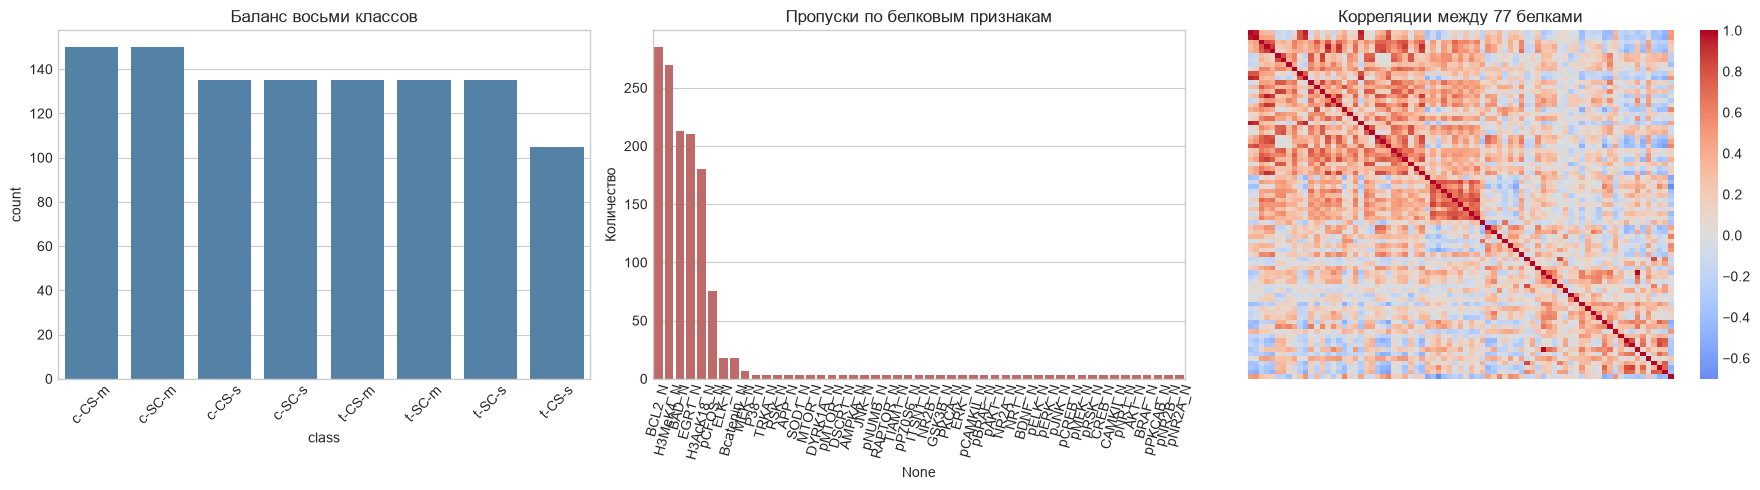

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.countplot(data=df, x="class", order=df["class"].value_counts().index, color="steelblue", ax=axes[0])
axes[0].set_title("Баланс восьми классов")
axes[0].tick_params(axis="x", rotation=45)

missing_nonzero = missing[missing > 0]
sns.barplot(x=missing_nonzero.index, y=missing_nonzero.values, color="indianred", ax=axes[1])
axes[1].set_title("Пропуски по белковым признакам")
axes[1].tick_params(axis="x", rotation=75)
axes[1].set_ylabel("Количество")

sns.heatmap(df[protein_cols].corr(), cmap="coolwarm", center=0, xticklabels=False, yticklabels=False, ax=axes[2])
axes[2].set_title("Корреляции между 77 белками")
plt.tight_layout(); plt.show()

## 2. Предобработка

Пропуски заполняются медианой соответствующего белкового признака. Затем применяется `StandardScaler`, поскольку PCA, Isomap, UMAP и алгоритмы кластеризации используют дисперсии или расстояния и чувствительны к масштабу. Масштабирование обучается только на признаках; метки классов в преобразованиях не участвуют.

In [4]:
X_imputed = SimpleImputer(strategy="median").fit_transform(df[protein_cols])
X_scaled = StandardScaler().fit_transform(X_imputed)

label_encoder = LabelEncoder()
y_true = label_encoder.fit_transform(df["class"])
class_names = label_encoder.classes_
n_clusters = len(class_names)

print("Форма матрицы признаков:", X_scaled.shape)
print("Число классов:", n_clusters)
print("Пропусков после импутации:", np.isnan(X_scaled).sum())
print("Среднее абсолютное значение средних после масштабирования:",
      f"{np.abs(X_scaled.mean(axis=0)).mean():.2e}")

Форма матрицы признаков: (1080, 77)
Число классов: 8
Пропусков после импутации: 0
Среднее абсолютное значение средних после масштабирования: 3.43e-16


## 3. Понижение размерности

Сравниваются четыре метода: линейный PCA, сохраняющий максимальную дисперсию; Isomap, использующий геодезические расстояния; UMAP, сохраняющий локальную топологию; t-SNE как двумерный визуализационный метод. Для кластеризации используются умеренно размерные представления PCA, Isomap и UMAP, а t-SNE включён отдельно, чтобы проверить риск кластеризации непосредственно на визуализационной проекции. Исходное стандартизованное пространство служит базовой линией.

20 компонент PCA были выбраны заранее как компромисс между сокращением 77 исходных признаков и сохранением большей части информации. После расчёта видно, что этого достаточно для объяснения 90.2% дисперсии. Для Isomap и UMAP я оставил по 10 компонент: это не результат предварительного подбора, а единая начальная размерность, которая заметно меньше исходной и при этом не сводит кластеризацию к двумерной картинке.

Значения `n_neighbors=15`, `min_dist=0.1` и `perplexity=30` также используются как стартовые. Дальше их влияние проверяется отдельным экспериментом, поэтому первоначальный выбор не считается оптимальным. t-SNE сразу строится в двух измерениях, так как здесь он нужен прежде всего для визуализации.

In [5]:
def fit_dr(method, n_components, **params):
    start = time.perf_counter()
    if method == "PCA":
        model = PCA(n_components=n_components, random_state=RANDOM_STATE)
    elif method == "Isomap":
        model = Isomap(n_components=n_components, n_neighbors=params.get("n_neighbors", 15))
    elif method == "UMAP":
        model = UMAP(
            n_components=n_components, n_neighbors=params.get("n_neighbors", 15),
            min_dist=params.get("min_dist", 0.1), random_state=RANDOM_STATE, n_jobs=1
        )
    elif method == "t-SNE":
        model = TSNE(
            n_components=2, perplexity=params.get("perplexity", 30),
            learning_rate="auto", init="pca", random_state=RANDOM_STATE
        )
    else:
        raise ValueError(method)
    embedding = model.fit_transform(X_scaled)
    elapsed = time.perf_counter() - start
    tw = trustworthiness(X_scaled, embedding, n_neighbors=10)
    return embedding, elapsed, tw, model


representations = {"Original_77D": X_scaled}
dr_models = {}
dr_rows = [["Original_77D", 77, 0.0, 1.0]]

dr_specs = {
    "PCA_20D": ("PCA", 20, {}),
    "Isomap_10D": ("Isomap", 10, {"n_neighbors": 15}),
    "UMAP_10D": ("UMAP", 10, {"n_neighbors": 15, "min_dist": 0.1}),
    "t-SNE_2D": ("t-SNE", 2, {"perplexity": 30}),
}

for name, (method, n_components, params) in dr_specs.items():
    embedding, elapsed, tw, model = fit_dr(method, n_components, **params)
    representations[name] = embedding
    dr_models[name] = model
    dr_rows.append([name, n_components, elapsed, tw])

dr_results = pd.DataFrame(dr_rows, columns=["Представление", "Размерность", "Время_с", "Trustworthiness@10"])
display(dr_results.style.format({"Время_с": "{:.3f}", "Trustworthiness@10": "{:.3f}"}))

pca_model = dr_models["PCA_20D"]
print(f"20 компонент PCA объясняют {pca_model.explained_variance_ratio_.sum():.1%} дисперсии")

,Представление,Размерность,Время_с,Trustworthiness@10
0,Original_77D,77,0.000,1.000
1,PCA_20D,20,0.030,0.999
2,Isomap_10D,10,0.803,0.995
3,UMAP_10D,10,16.360,0.986
4,t-SNE_2D,2,6.563,0.990


20 компонент PCA объясняют 90.2% дисперсии


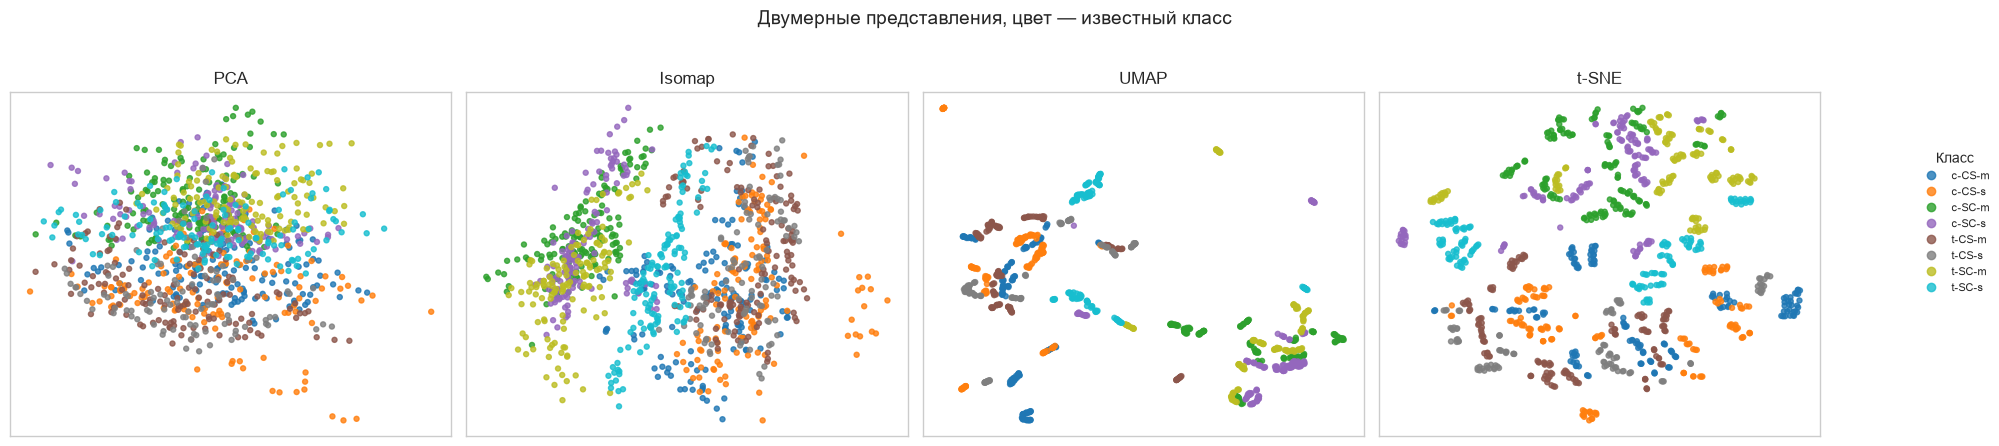

In [6]:
visual_2d = {
    "PCA": PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_scaled),
    "Isomap": Isomap(n_components=2, n_neighbors=15).fit_transform(X_scaled),
    "UMAP": UMAP(n_components=2, n_neighbors=15, min_dist=0.1,
                 random_state=RANDOM_STATE, n_jobs=1).fit_transform(X_scaled),
    "t-SNE": representations["t-SNE_2D"],
}

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, (name, embedding) in zip(axes, visual_2d.items()):
    scatter = ax.scatter(embedding[:, 0], embedding[:, 1], c=y_true, cmap="tab10", s=13, alpha=0.8)
    ax.set_title(name)
    ax.set_xticks([]); ax.set_yticks([])
handles, _ = scatter.legend_elements(num=n_clusters)
fig.legend(handles, class_names, title="Класс", loc="center right", fontsize=8)
fig.suptitle("Двумерные представления, цвет — известный класс", fontsize=14)
plt.tight_layout(rect=[0, 0, 0.92, 0.95]); plt.show()

На PCA и Isomap классы заметно пересекаются. UMAP и t-SNE показывают более выраженные локальные группы, но полного разделения восьми цветов всё равно нет. Поэтому двумерные графики полезны для первичного сравнения, однако вывод о качестве кластеризации дальше проверяется метриками в исходном или многомерном сокращённом пространстве.

## 4. Сравнение пайплайнов «DR → кластеризация»

Используются четыре алгоритма: KMeans, агломеративная кластеризация, Gaussian Mixture Model и BIRCH. Число кластеров установлено равным восьми — числу известных экспериментальных групп. Внутренние метрики оценивают геометрию без разметки, а ARI, AMI, homogeneity, completeness и V-measure сравнивают найденные группы с разметкой. Классы не используются при обучении моделей.

Восемь кластеров сначала выбраны для прямого сравнения с восемью известными группами мышей. Это не предположение о том, что в данных обязательно есть ровно восемь естественных кластеров; ниже число групп дополнительно проверяется по silhouette. Остальные настройки алгоритмов зафиксированы для честного сравнения представлений: например, `n_init=20` уменьшает зависимость KMeans от старта, а диагональная ковариация GMM делает оценивание устойчивее при ограниченном числе объектов.

In [7]:
def make_clusterer(name, k=n_clusters, seed=RANDOM_STATE):
    if name == "KMeans":
        return KMeans(n_clusters=k, n_init=20, random_state=seed)
    if name == "Agglomerative":
        return AgglomerativeClustering(n_clusters=k, linkage="ward")
    if name == "GMM":
        return GaussianMixture(n_components=k, covariance_type="diag", n_init=5, random_state=seed)
    if name == "BIRCH":
        return Birch(n_clusters=k, threshold=0.5)
    raise ValueError(name)


def evaluate_labels(X, labels, y, representation, algorithm, elapsed):
    return {
        "Представление": representation,
        "Алгоритм": algorithm,
        "Silhouette": silhouette_score(X, labels),
        "Calinski_Harabasz": calinski_harabasz_score(X, labels),
        "Davies_Bouldin": davies_bouldin_score(X, labels),
        "ARI": adjusted_rand_score(y, labels),
        "AMI": adjusted_mutual_info_score(y, labels),
        "Homogeneity": homogeneity_score(y, labels),
        "Completeness": completeness_score(y, labels),
        "V_measure": v_measure_score(y, labels),
        "Время_с": elapsed,
    }


algorithms = ["KMeans", "Agglomerative", "GMM", "BIRCH"]
benchmark_rows = []
cluster_labels = {}

for representation, X_dr in representations.items():
    for algorithm in algorithms:
        start = time.perf_counter()
        labels = make_clusterer(algorithm).fit_predict(X_dr)
        elapsed = time.perf_counter() - start
        cluster_labels[(representation, algorithm)] = labels
        benchmark_rows.append(evaluate_labels(X_dr, labels, y_true, representation, algorithm, elapsed))

results_df = pd.DataFrame(benchmark_rows)
display(results_df.sort_values("ARI", ascending=False).style.format({
    "Silhouette": "{:.3f}", "Calinski_Harabasz": "{:.1f}", "Davies_Bouldin": "{:.3f}",
    "ARI": "{:.3f}", "AMI": "{:.3f}", "Homogeneity": "{:.3f}",
    "Completeness": "{:.3f}", "V_measure": "{:.3f}", "Время_с": "{:.3f}"
}))

,Представление,Алгоритм,Silhouette,Calinski_Harabasz,Davies_Bouldin,ARI,AMI,Homogeneity,Completeness,V_measure,Время_с
15,UMAP_10D,BIRCH,0.532,1280.4,0.527,0.246,0.416,0.381,0.478,0.424,0.049
16,t-SNE_2D,KMeans,0.430,1298.1,0.772,0.245,0.427,0.431,0.435,0.433,0.083
19,t-SNE_2D,BIRCH,0.406,1197.4,0.779,0.244,0.415,0.416,0.428,0.422,0.068
14,UMAP_10D,GMM,0.566,1226.9,0.529,0.239,0.423,0.383,0.494,0.431,0.064
17,t-SNE_2D,Agglomerative,0.412,1187.0,0.788,0.238,0.409,0.409,0.422,0.416,0.024
13,UMAP_10D,Agglomerative,0.532,1260.9,0.493,0.237,0.427,0.386,0.499,0.435,0.032
12,UMAP_10D,KMeans,0.531,1315.8,0.505,0.233,0.410,0.374,0.472,0.417,0.095
18,t-SNE_2D,GMM,0.404,1155.7,0.791,0.232,0.428,0.426,0.442,0.434,0.060
11,Isomap_10D,BIRCH,0.212,192.5,1.469,0.223,0.415,0.406,0.439,0.422,0.134
9,Isomap_10D,Agglomerative,0.203,182.7,1.550,0.212,0.404,0.397,0.426,0.411,0.027


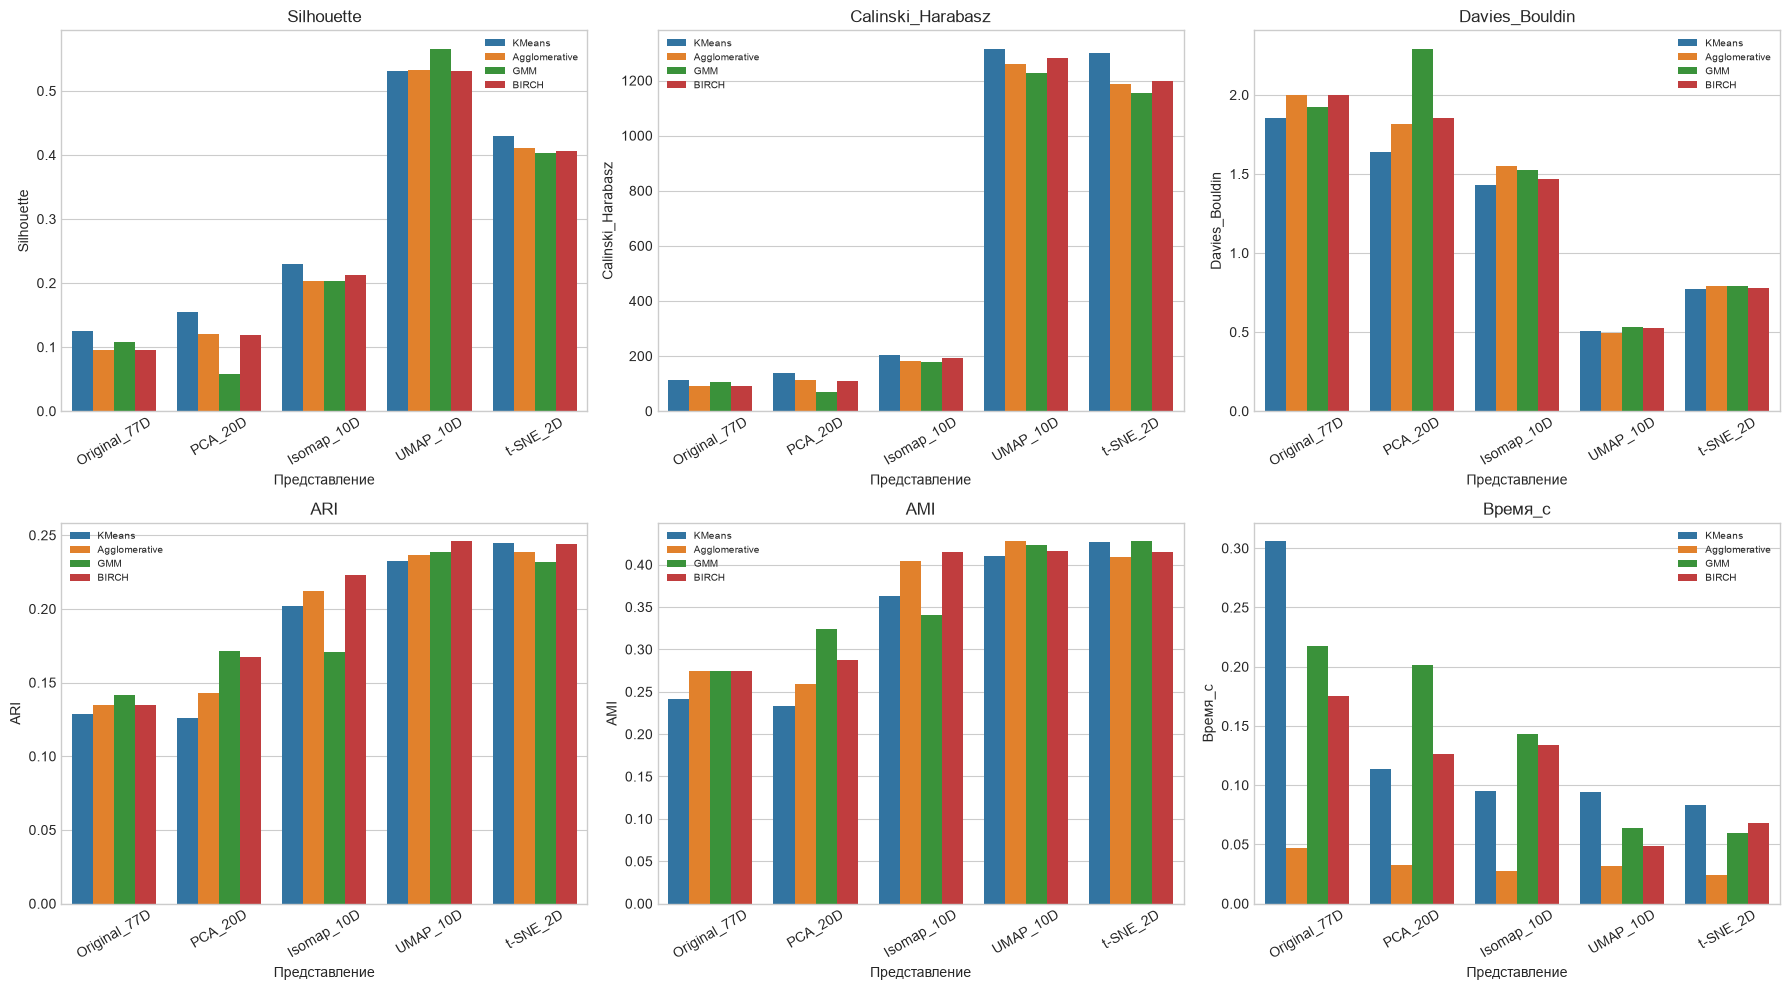

Лучшая комбинация по каждой основной метрике:


,Метрика,Представление,Алгоритм,Значение
0,Silhouette,UMAP_10D,GMM,0.566
1,Calinski_Harabasz,UMAP_10D,KMeans,1315.822
2,Davies_Bouldin,UMAP_10D,Agglomerative,0.493
3,ARI,UMAP_10D,BIRCH,0.246
4,AMI,t-SNE_2D,GMM,0.428


In [8]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, metric in zip(axes.ravel(), ["Silhouette", "Calinski_Harabasz", "Davies_Bouldin", "ARI", "AMI", "Время_с"]):
    sns.barplot(data=results_df, x="Представление", y=metric, hue="Алгоритм", ax=ax, errorbar=None)
    ax.set_title(metric)
    ax.tick_params(axis="x", rotation=30)
    ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

print("Лучшая комбинация по каждой основной метрике:")
best_rows = []
for metric, ascending in {"Silhouette": False, "Calinski_Harabasz": False,
                           "Davies_Bouldin": True, "ARI": False, "AMI": False}.items():
    row = results_df.sort_values(metric, ascending=ascending).iloc[0]
    best_rows.append([metric, row["Представление"], row["Алгоритм"], row[metric]])
display(pd.DataFrame(best_rows, columns=["Метрика", "Представление", "Алгоритм", "Значение"])
        .style.format({"Значение": "{:.3f}"}))

Численные результаты совпадают с общим впечатлением от проекций: варианты на UMAP дают лучшие silhouette и ARI, а PCA и исходное пространство разделяют группы слабее. Но даже максимальный ARI остаётся около 0.25, то есть найденные кластеры только частично соответствуют восьми классам. t-SNE выглядит конкурентно, хотя его двумерную геометрию нельзя считать надёжным отображением глобальных расстояний.

## 5. Чувствительность к числу кластеров и параметрам DR

Сначала меняется только число кластеров KMeans, чтобы не смешивать эффект `k` с выбором алгоритма. Затем при фиксированных восьми кластерах проверяются параметры Isomap, UMAP и t-SNE. То есть размерности и стартовые параметры выше были заданы заранее, а этот раздел уже является экспериментальной проверкой их чувствительности.

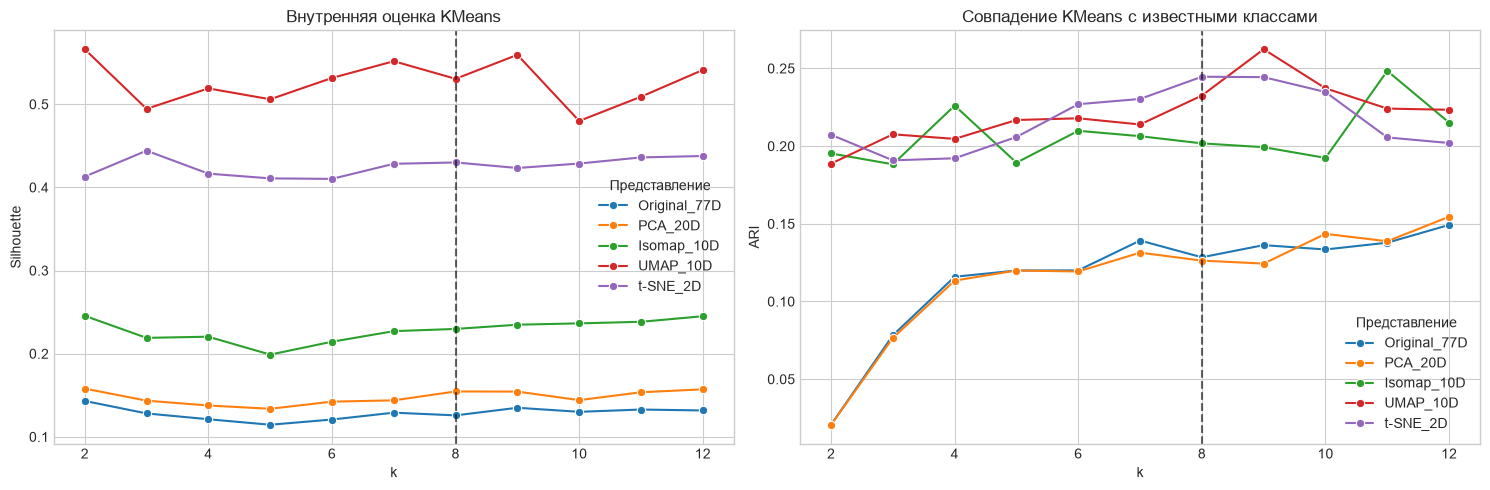

,Представление,k,Silhouette,ARI
33,UMAP_10D,2,0.566,0.189
45,t-SNE_2D,3,0.444,0.191
22,Isomap_10D,2,0.245,0.195
11,PCA_20D,2,0.158,0.021
0,Original_77D,2,0.143,0.021


In [9]:
k_rows = []
for representation, X_dr in representations.items():
    for k in range(2, 13):
        labels = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit_predict(X_dr)
        k_rows.append({
            "Представление": representation, "k": k,
            "Silhouette": silhouette_score(X_dr, labels),
            "ARI": adjusted_rand_score(y_true, labels)
        })
k_results = pd.DataFrame(k_rows)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.lineplot(data=k_results, x="k", y="Silhouette", hue="Представление", marker="o", ax=axes[0])
sns.lineplot(data=k_results, x="k", y="ARI", hue="Представление", marker="o", ax=axes[1])
axes[0].axvline(n_clusters, color="black", linestyle="--", alpha=0.6)
axes[1].axvline(n_clusters, color="black", linestyle="--", alpha=0.6)
axes[0].set_title("Внутренняя оценка KMeans")
axes[1].set_title("Совпадение KMeans с известными классами")
plt.tight_layout(); plt.show()

best_k_internal = k_results.loc[k_results.groupby("Представление")["Silhouette"].idxmax()]
display(best_k_internal.sort_values("Silhouette", ascending=False).style.format({"Silhouette": "{:.3f}", "ARI": "{:.3f}"}))

По silhouette KMeans предпочитает два кластера почти для всех представлений; у t-SNE максимум получен при трёх. Вертикальная линия при `k=8` показывает исходное число экспериментальных групп, но внутренней геометрией оно не подтверждается. Поэтому восемь кластеров нужны прежде всего для сопоставления с разметкой, а не как найденное оптимальное число групп.

C:\Users\1\anaconda3\Lib\site-packages\sklearn\manifold\_isomap.py:386: UserWarning: The number of connected components of the neighbors graph is 16 > 1. Completing the graph to fit Isomap might be slow. Increase the number of neighbors to avoid this issue.
  self._fit_transform(X)
C:\Users\1\anaconda3\Lib\site-packages\scipy\sparse\_index.py:174: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])
C:\Users\1\anaconda3\Lib\site-packages\scipy\sparse\_index.py:174: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])
C:\Users\1\anaconda3\Lib\site-packages\scipy\sparse\_index.py:174: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])
C:\Users\1\anaconda3\Lib\site-packag

,Метод,Конфигурация,Silhouette,ARI,Trustworthiness@10,Время_с
1,Isomap,Isomap: n_neighbors=10,0.257,0.251,0.993,0.73
2,Isomap,Isomap: n_neighbors=20,0.199,0.216,0.995,0.81
3,Isomap,Isomap: n_neighbors=40,0.185,0.211,0.996,1.25
0,Isomap,Isomap: n_neighbors=5,0.357,0.130,0.966,0.93
7,UMAP,"UMAP: n_neighbors=15, min_dist=0.5",0.419,0.255,0.990,4.20
9,UMAP,"UMAP: n_neighbors=40, min_dist=0.5",0.324,0.243,0.989,5.08
8,UMAP,"UMAP: n_neighbors=40, min_dist=0.0",0.467,0.239,0.987,5.11
6,UMAP,"UMAP: n_neighbors=15, min_dist=0.0",0.574,0.231,0.984,4.10
5,UMAP,"UMAP: n_neighbors=5, min_dist=0.5",0.268,0.145,0.961,3.31
4,UMAP,"UMAP: n_neighbors=5, min_dist=0.0",0.256,0.133,0.952,3.79


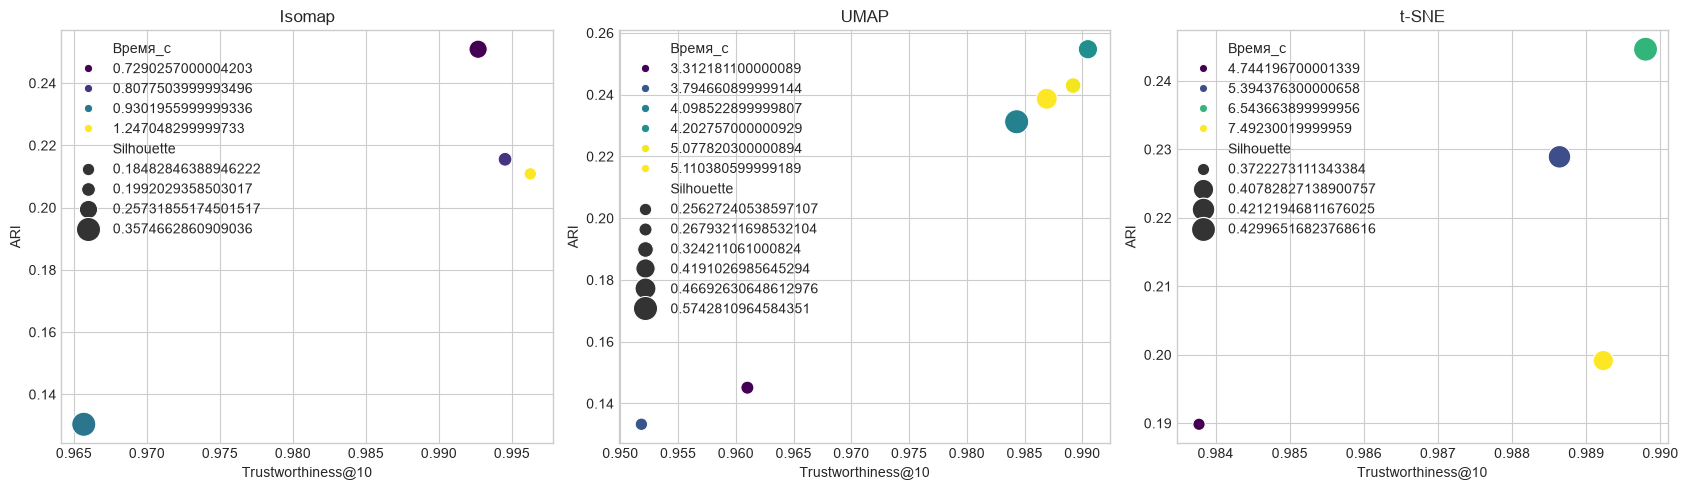

In [10]:
parameter_rows = []
parameter_embeddings = {}

parameter_grid = (
    [("Isomap", {"n_neighbors": n}) for n in [5, 10, 20, 40]] +
    [("UMAP", {"n_neighbors": n, "min_dist": d}) for n in [5, 15, 40] for d in [0.0, 0.5]] +
    [("t-SNE", {"perplexity": p}) for p in [5, 15, 30, 50]]
)

for method, params in parameter_grid:
    n_components = 2 if method == "t-SNE" else 10
    embedding, elapsed, tw, _ = fit_dr(method, n_components, **params)
    labels = KMeans(n_clusters=n_clusters, n_init=20, random_state=RANDOM_STATE).fit_predict(embedding)
    config = method + ": " + ", ".join(f"{k}={v}" for k, v in params.items())
    parameter_embeddings[config] = embedding
    parameter_rows.append({
        "Метод": method, "Конфигурация": config,
        "Silhouette": silhouette_score(embedding, labels),
        "ARI": adjusted_rand_score(y_true, labels),
        "Trustworthiness@10": tw, "Время_с": elapsed
    })

parameter_results = pd.DataFrame(parameter_rows)
display(parameter_results.sort_values(["Метод", "ARI"], ascending=[True, False]).style.format({
    "Silhouette": "{:.3f}", "ARI": "{:.3f}", "Trustworthiness@10": "{:.3f}", "Время_с": "{:.2f}"
}))

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, method in zip(axes, ["Isomap", "UMAP", "t-SNE"]):
    subset = parameter_results[parameter_results["Метод"] == method]
    sns.scatterplot(data=subset, x="Trustworthiness@10", y="ARI", size="Silhouette",
                    hue="Время_с", palette="viridis", sizes=(80, 300), ax=ax)
    ax.set_title(method)
plt.tight_layout(); plt.show()

Результат действительно зависит от параметров. Для UMAP лучший ARI у KMeans получен при `n_neighbors=15` и `min_dist=0.5` (0.255), для Isomap — при `n_neighbors=10` (0.251), а для t-SNE — при `perplexity=30` (0.245). При этом конфигурация с лучшим silhouette не всегда имеет лучший ARI, потому что компактные геометрические группы могут не совпадать с экспериментальными классами.

## 6. Устойчивость кластеризации

Для каждой комбинации выполняется десять независимых 80%-х подвыборок без возвращения. Разбиение на подвыборке сравнивается по ARI с соответствующей частью разбиения, полученного на полном наборе. Для KMeans и GMM одновременно меняется случайная инициализация; для детерминированных Agglomerative и BIRCH измеряется чувствительность к составу выборки.

,Представление,Алгоритм,Устойчивость_mean,Устойчивость_std
15,UMAP_10D,KMeans,0.977,0.031
13,UMAP_10D,BIRCH,0.955,0.033
12,UMAP_10D,Agglomerative,0.907,0.049
18,t-SNE_2D,GMM,0.906,0.101
17,t-SNE_2D,BIRCH,0.882,0.066
19,t-SNE_2D,KMeans,0.864,0.123
14,UMAP_10D,GMM,0.853,0.067
11,PCA_20D,KMeans,0.789,0.110
1,Isomap_10D,BIRCH,0.758,0.096
16,t-SNE_2D,Agglomerative,0.732,0.061


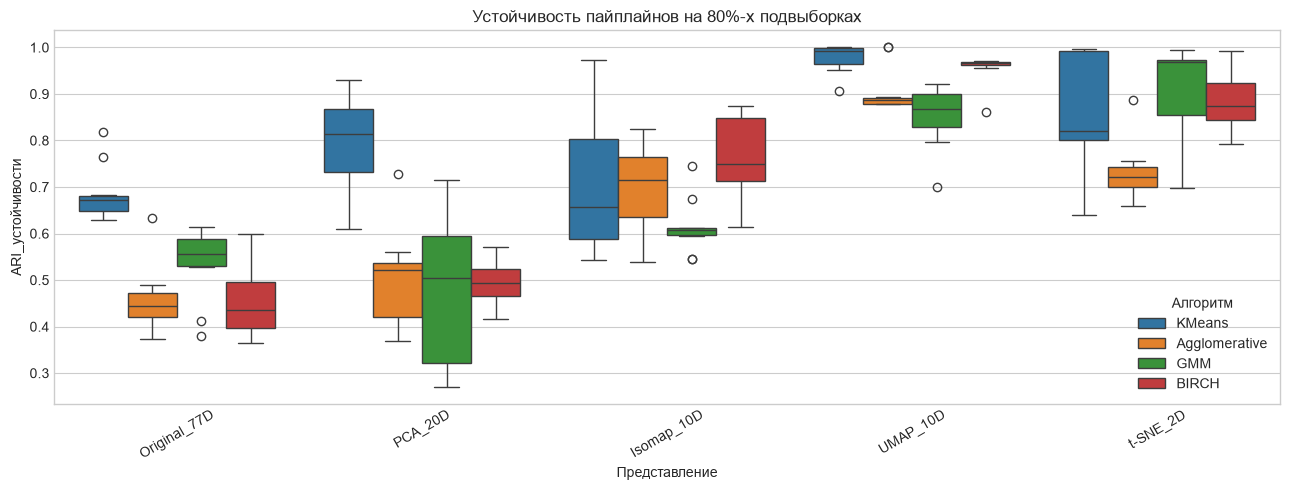

In [11]:
rng = np.random.default_rng(RANDOM_STATE)
stability_rows = []

for representation, X_dr in representations.items():
    for algorithm in algorithms:
        reference_labels = cluster_labels[(representation, algorithm)]
        for iteration in range(10):
            idx = rng.choice(len(X_dr), size=int(0.8 * len(X_dr)), replace=False)
            sampled_labels = make_clusterer(algorithm, seed=100 + iteration).fit_predict(X_dr[idx])
            stability_rows.append({
                "Представление": representation,
                "Алгоритм": algorithm,
                "Итерация": iteration,
                "ARI_устойчивости": adjusted_rand_score(reference_labels[idx], sampled_labels)
            })

stability_runs = pd.DataFrame(stability_rows)
stability_df = stability_runs.groupby(["Представление", "Алгоритм"])["ARI_устойчивости"].agg(["mean", "std"]).reset_index()
stability_df.columns = ["Представление", "Алгоритм", "Устойчивость_mean", "Устойчивость_std"]
display(stability_df.sort_values("Устойчивость_mean", ascending=False).style.format({
    "Устойчивость_mean": "{:.3f}", "Устойчивость_std": "{:.3f}"
}))

plt.figure(figsize=(13, 5))
sns.boxplot(data=stability_runs, x="Представление", y="ARI_устойчивости", hue="Алгоритм")
plt.xticks(rotation=30)
plt.title("Устойчивость пайплайнов на 80%-х подвыборках")
plt.tight_layout(); plt.show()

UMAP даёт наиболее устойчивые результаты: средний ARI равен 0.977 для KMeans и 0.955 для BIRCH. У исходного пространства и PCA разброс больше, поэтому их разбиения сильнее зависят от состава выборки. Высокая устойчивость сама по себе ещё не означает совпадение с классами, но показывает, что найденная структура воспроизводится.

## 7. Комплексное ранжирование пайплайнов

Одной метрики здесь недостаточно. ARI и AMI показывают соответствие известным экспериментальным классам, а silhouette оценивает компактность и разделимость кластеров без использования этих меток. Поэтому они используются как основные критерии качества и вместе получают 70% веса: ARI — 30%, AMI — 20%, silhouette — 20%.

Дополнительные критерии — устойчивость на подвыборках (20%) и время кластеризации (10%). Перед сложением все показатели приводятся к диапазону от 0 до 1, причём меньшее время считается лучшим. Эти веса выбраны автором для удобства итогового сравнения и не являются общепринятым стандартом. Полученный балл — не объективная мера качества кластеризации, а способ увидеть разумный компромисс между несколькими свойствами.

,Представление,Алгоритм,Silhouette,ARI,AMI,Устойчивость_mean,Время_с,Комплексная_оценка
1,UMAP_10D,BIRCH,0.532,0.246,0.416,0.955,0.049,0.957
2,UMAP_10D,Agglomerative,0.532,0.237,0.427,0.907,0.032,0.933
3,UMAP_10D,GMM,0.566,0.239,0.423,0.853,0.064,0.916
4,UMAP_10D,KMeans,0.531,0.233,0.410,0.977,0.095,0.908
5,t-SNE_2D,KMeans,0.430,0.245,0.427,0.864,0.083,0.877
6,t-SNE_2D,BIRCH,0.406,0.244,0.415,0.882,0.068,0.866
7,t-SNE_2D,GMM,0.404,0.232,0.428,0.906,0.060,0.861
8,t-SNE_2D,Agglomerative,0.412,0.238,0.409,0.732,0.024,0.806
9,Isomap_10D,BIRCH,0.212,0.223,0.415,0.758,0.134,0.667
10,Isomap_10D,Agglomerative,0.203,0.212,0.404,0.700,0.027,0.640


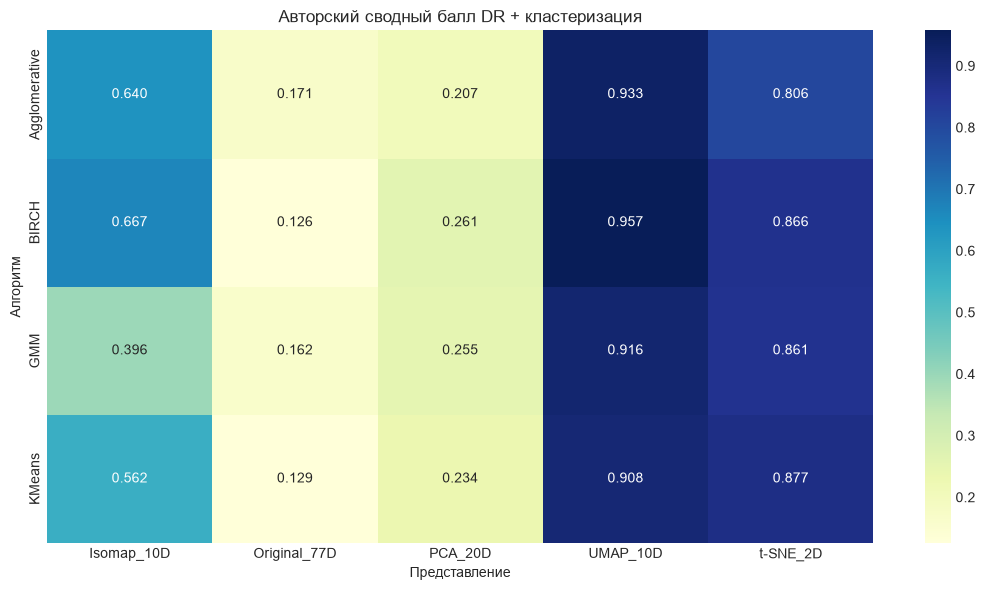

In [12]:
ranking = results_df.merge(stability_df, on=["Представление", "Алгоритм"])
ranking["Inv_Время"] = -ranking["Время_с"]

# Основные критерии качества: ARI, AMI и silhouette (в сумме 70%).
# Дополнительные критерии: устойчивость и вычислительное время (30%).
score_columns = ["ARI", "AMI", "Silhouette", "Устойчивость_mean", "Inv_Время"]
weights = np.array([0.30, 0.20, 0.20, 0.20, 0.10])

normalized = MinMaxScaler().fit_transform(ranking[score_columns])
ranking["Комплексная_оценка"] = normalized @ weights
ranking = ranking.sort_values("Комплексная_оценка", ascending=False).reset_index(drop=True)
ranking.index = ranking.index + 1

display(ranking[["Представление", "Алгоритм", "Silhouette", "ARI", "AMI",
                 "Устойчивость_mean", "Время_с", "Комплексная_оценка"]]
        .style.format({"Silhouette": "{:.3f}", "ARI": "{:.3f}", "AMI": "{:.3f}",
                       "Устойчивость_mean": "{:.3f}", "Время_с": "{:.3f}",
                       "Комплексная_оценка": "{:.3f}"}))

pivot = ranking.pivot(index="Алгоритм", columns="Представление", values="Комплексная_оценка")
plt.figure(figsize=(11, 6))
sns.heatmap(pivot, annot=True, fmt=".3f", cmap="YlGnBu")
plt.title("Авторский сводный балл DR + кластеризация")
plt.tight_layout(); plt.show()

## 8. Интерпретация лучшего решения

Кластеры интерпретируются в исходном пространстве белков. Для каждого признака рассчитывается доля дисперсии, объясняемая различиями между найденными кластерами (аналог однофакторного $\eta^2$). Затем показываются профили белков с максимальными значениями этой меры и состав кластеров по известным экспериментальным группам.

,Белок,eta_squared
20,BRAF_N,0.755
0,DYRK1A_N,0.734
10,pERK_N,0.721
1,ITSN1_N,0.646
50,AcetylH3K9_N,0.634
17,pPKCAB_N,0.631
46,pPKCG_N,0.605
76,CaNA_N,0.574
9,pELK_N,0.512
25,GSK3B_N,0.499


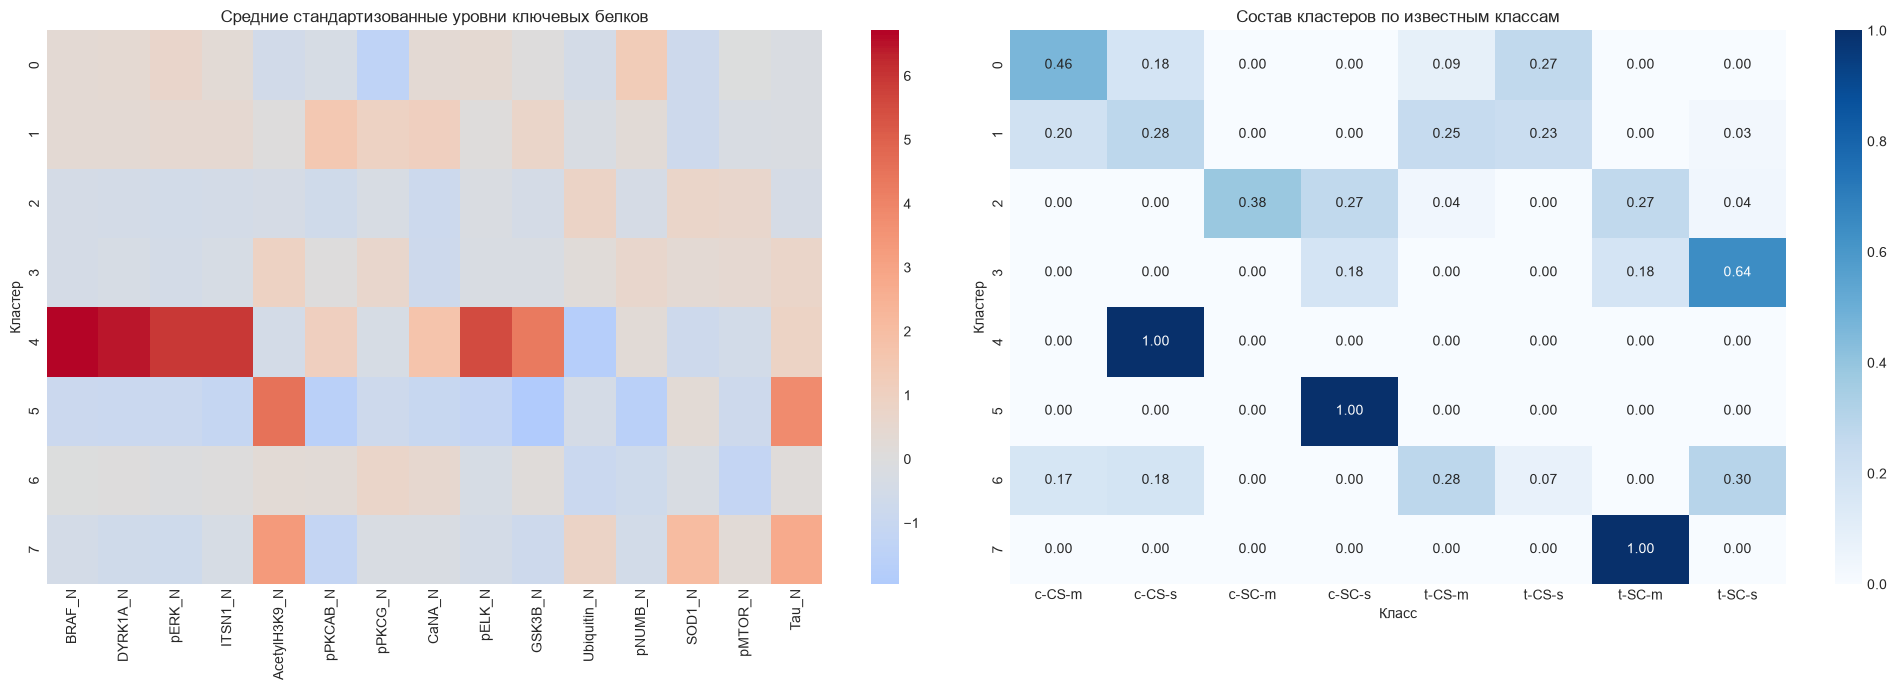

Лучший пайплайн: UMAP_10D + BIRCH


,Размер
0,168
1,193
2,390
3,84
4,15
5,15
6,200
7,15


In [13]:
best_representation = ranking.iloc[0]["Представление"]
best_algorithm = ranking.iloc[0]["Алгоритм"]
best_labels = cluster_labels[(best_representation, best_algorithm)]

global_mean = X_scaled.mean(axis=0)
ss_total = ((X_scaled - global_mean) ** 2).sum(axis=0)
ss_between = np.zeros(X_scaled.shape[1])
for cluster_id in np.unique(best_labels):
    mask = best_labels == cluster_id
    cluster_mean = X_scaled[mask].mean(axis=0)
    ss_between += mask.sum() * (cluster_mean - global_mean) ** 2
eta_squared = np.divide(ss_between, ss_total, out=np.zeros_like(ss_between), where=ss_total > 0)

feature_importance = pd.DataFrame({"Белок": protein_cols, "eta_squared": eta_squared}).sort_values("eta_squared", ascending=False)
top_features = feature_importance.head(15)["Белок"].tolist()
display(feature_importance.head(20).style.format({"eta_squared": "{:.3f}"}))

profile = pd.DataFrame(X_scaled, columns=protein_cols).assign(Кластер=best_labels).groupby("Кластер")[top_features].mean()
composition = pd.crosstab(
    pd.Series(best_labels, name="Кластер"),
    pd.Series(df["class"].to_numpy(), name="Класс"),
    normalize="index"
)

fig, axes = plt.subplots(1, 2, figsize=(20, 7))
sns.heatmap(profile, cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Средние стандартизованные уровни ключевых белков")
sns.heatmap(composition, cmap="Blues", annot=True, fmt=".2f", ax=axes[1])
axes[1].set_title("Состав кластеров по известным классам")
plt.tight_layout(); plt.show()

cluster_sizes = pd.Series(best_labels).value_counts().sort_index().rename("Размер")
print(f"Лучший пайплайн: {best_representation} + {best_algorithm}")
display(cluster_sizes.to_frame())

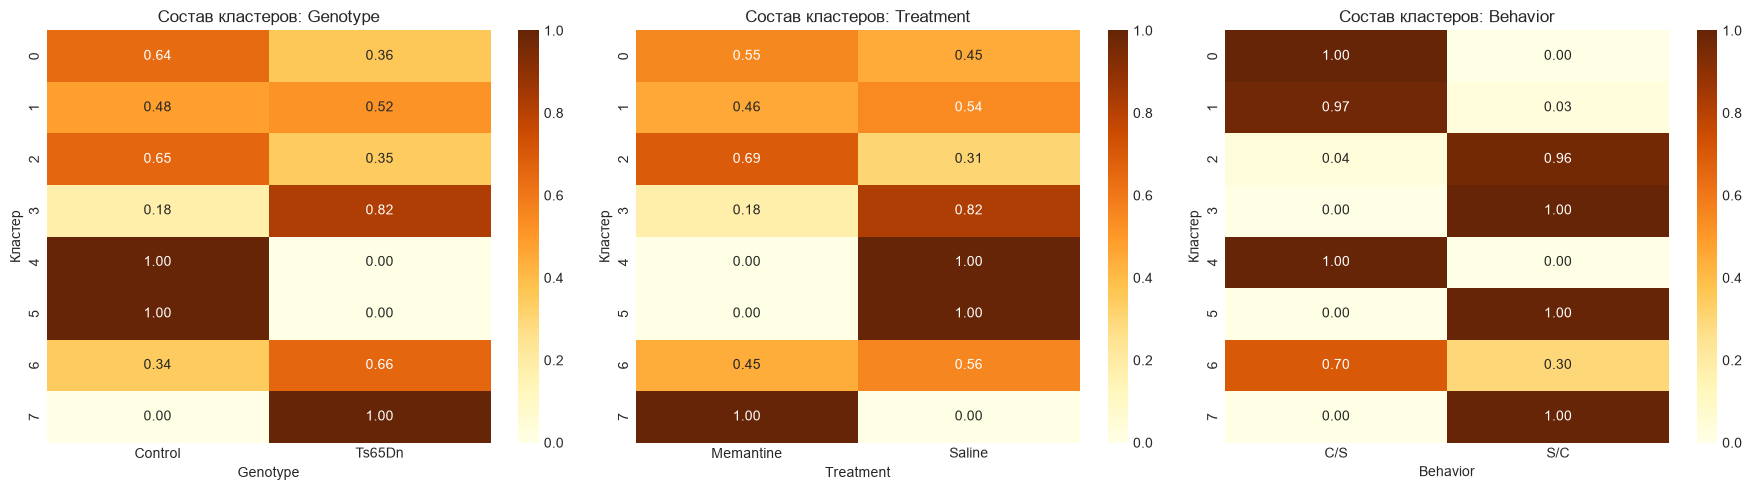

In [14]:
# Дополнительная интерпретация экспериментальных факторов.
factor_tables = {}
for factor in ["Genotype", "Treatment", "Behavior"]:
    factor_tables[factor] = pd.crosstab(
        pd.Series(best_labels, name="Кластер"),
        pd.Series(df[factor].to_numpy(), name=factor),
        normalize="index"
    )

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (factor, table) in zip(axes, factor_tables.items()):
    sns.heatmap(table, annot=True, fmt=".2f", cmap="YlOrBr", vmin=0, vmax=1, ax=ax)
    ax.set_title(f"Состав кластеров: {factor}")
plt.tight_layout(); plt.show()

## 9. Выводы

В наборе обнаружено 1396 пропусков в 49 из 77 белковых признаков. После медианной импутации и стандартизации в матрице не осталось пропусков; категориальные экспериментальные признаки и метка класса не использовались при обучении. Первые 20 компонент PCA объясняют 90.2% дисперсии. Локальные соседства сохранились при Isomap (trustworthiness=0.995), t-SNE (0.990) и UMAP (0.986).

По авторскому сводному баллу первым стал **UMAP_10D + BIRCH**: итоговый балл 0.957, silhouette=0.532, ARI=0.246, AMI=0.416 и средняя устойчивость 0.955. Этот балл нужен только для удобного сравнения и не является объективной метрикой качества. Остальные варианты на UMAP также заняли первые четыре позиции. Максимальный silhouette показал UMAP_10D + GMM (0.566), а максимальный ARI — UMAP_10D + BIRCH (0.246).

Подбор параметров показал чувствительность результатов: для KMeans лучший ARI среди проверенных вариантов UMAP равен 0.255 при n_neighbors=15 и min_dist=0.5; для Isomap — 0.251 при n_neighbors=10; для t-SNE — 0.245 при perplexity=30. Однако максимум silhouette при свободном выборе числа кластеров достигается преимущественно при k=2 (для t-SNE — при k=3), а не при восьми классах. Следовательно, восемь экспериментальных групп не образуют восемь естественно компактных геометрических кластеров.

Устойчивость заметно различается между пайплайнами. Наиболее стабилен UMAP_10D + KMeans (средний ARI между полным разбиением и разбиениями подвыборок 0.977), затем UMAP_10D + BIRCH (0.955). Представления PCA и исходное 77-мерное пространство в среднем дали и более низкое совпадение с классами, и меньшую устойчивость.

Для лучшего решения наиболее различающими кластеры белками оказались BRAF_N, DYRK1A_N, pERK_N, ITSN1_N и AcetylH3K9_N. Размеры кластеров неодинаковы — от 15 до 390 объектов, поэтому небольшие группы следует интерпретировать осторожно. Тепловые карты показывают как разные белковые профили, так и смешанный состав некоторых кластеров по экспериментальным классам.